# Before the Breach: Exploration Notebook
**IBM Track, Sheridan Datathon 2026**

**Question to answer:** if a security team can only fix a small number of vulnerabilities, which ones should they fix, and why is that better than sorting by CVSS?

How to use this notebook: run top to bottom. Each section ends with a **"What to look for"** note and a blank **Finding** line. Fill those in as you go. The best 3-4 findings become your demo.

| Section | Goal |
|---|---|
| 0 | Setup and load |
| 1 | Build the backtest snapshot (2024-2025) and understand the labels |
| 2 | Reproduce the baselines (CVSS, EPSS, exploit code) |
| 3 | Does severity separate exploited from not-exploited at all? |
| 4 | Concentration: vendors, weakness types, attack details |
| 5 | Leakage check: which NIST columns give the answer away? |
| 6 | Momentum: does a vendor's recent KEV history predict the next one? |
| 7 | Description text: do phrases carry signal? |
| 8 | Look at the 2026 scoreboard |

**Core rule:** a feature is only allowed if it was known at the end of the vulnerability's `snapshot_month`.

## 0. Setup and load

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

DATA_DIR = Path("data") if Path("data").exists() else Path("../data")  # change if you unzipped somewhere else
LABEL_END = pd.Timestamp("2025-12-31")   # KEV list in the data stops here
RNG = np.random.default_rng(42)

In [2]:
vuln = pd.read_csv(DATA_DIR / "vulnerabilities.csv", parse_dates=["published", "last_modified"])
kev = pd.read_csv(DATA_DIR / "known_exploited.csv", parse_dates=["date_added", "due_date"])
sig = pd.concat([
    pd.read_csv(DATA_DIR / "exploit_signals_2024.csv"),
    pd.read_csv(DATA_DIR / "exploit_signals_2025.csv"),
], ignore_index=True)
cwe_names = pd.read_csv(DATA_DIR / "weakness_types.csv")[["cwe_id", "name"]]
board = pd.read_csv(DATA_DIR / "scoreboard_2026.csv", parse_dates=["published"])

print("vuln", vuln.shape, "| kev", kev.shape, "| signals", sig.shape, "| scoreboard", board.shape)
print("KEV date range:", kev.date_added.min().date(), "to", kev.date_added.max().date())
print("Share of KEV ids present in vulnerabilities.csv:", round(kev.cve_id.isin(vuln.cve_id).mean(), 3))

vuln (401082, 30) | kev (1484, 10) | signals (6463734, 8) | scoreboard (72670, 8)
KEV date range: 2021-11-03 to 2025-12-29
Share of KEV ids present in vulnerabilities.csv: 1.0


## 1. Build the backtest snapshot and understand the labels

For every vulnerability **published in 2024-2025**, attach the signals from **the end of its publish month** (the same thing the 2026 scoreboard does). The label is "added to KEV after that month ended".

Rows already on KEV at snapshot are dropped, which mirrors how the scoreboard was built.

**Caveats baked in:**
- Late-2025 vulnerabilities have had little time to be exploited (right-censoring). Use `published <= 2025-06-30` when you want a fair label.
- February 2025 signals are missing about 14,500 vulnerabilities, so some Feb-2025 rows will have no signal row.

In [3]:
v = vuln[(vuln.published >= "2024-01-01") & (vuln.published <= LABEL_END)].copy()
v["snapshot_month"] = v.published.dt.strftime("%Y-%m")
v["month_end"] = v.published.dt.to_period("M").dt.end_time.dt.normalize()

snap = v.merge(
    sig.rename(columns={"month": "sig_month"}),
    left_on=["cve_id", "snapshot_month"], right_on=["cve_id", "sig_month"], how="left",
)
snap["has_signal_row"] = snap.sig_month.notna()
for c in ["in_kev", "exploitdb", "metasploit", "nuclei", "poc_github"]:
    snap[c] = snap[c].fillna(0).astype(int)
snap = snap.drop(columns="sig_month")

# KEV date from CISA list (more reliable than the monthly in_kev flag, which is missing for Feb 2025 rows)
snap = snap.merge(kev[["cve_id", "date_added"]].rename(columns={"date_added": "kev_date"}), on="cve_id", how="left")

# drop vulnerabilities that were already on KEV by the end of their snapshot month
already = snap.kev_date.notna() & (snap.kev_date <= snap.month_end)
print("Dropped (already on KEV at snapshot):", int(already.sum()))
snap = snap[~already].copy()

snap["label"] = snap.kev_date.notna().astype(int)
snap["days_to_kev"] = (snap.kev_date - snap.published).dt.days
snap["any_exploit_code"] = (snap[["exploitdb", "metasploit", "nuclei", "poc_github"]].sum(axis=1) > 0).astype(int)
snap["days_exposed"] = (LABEL_END - snap.published).dt.days

print(f"Snapshot rows: {len(snap):,} | later added to KEV: {snap.label.sum()} | base rate: {100*snap.label.mean():.3f}%")
print("Rows with no signal row:", int((~snap.has_signal_row).sum()))
snap.groupby("snapshot_month").agg(n=("cve_id", "size"), kev=("label", "sum"), no_signal=("has_signal_row", lambda s: (~s).sum())).T

Dropped (already on KEV at snapshot): 195
Snapshot rows: 87,908 | later added to KEV: 122 | base rate: 0.139%
Rows with no signal row: 5807


snapshot_month,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
n,2585,2773,3305,3612,4991,3075,3105,2885,2508,3554,4048,3427,4267,3664,3982,4024,3968,3674,3768,3621,4313,4267,3015,5477
kev,5,5,3,1,5,9,3,8,7,6,8,7,7,6,7,5,6,8,2,5,6,2,1,0
no_signal,121,62,63,74,476,103,255,30,68,62,28,98,1909,852,329,98,18,48,77,27,102,78,13,816


### 1a. KEV additions over time and time-to-KEV
**What to look for:** how bursty KEV additions are, how many are added within 30 / 90 days of publication, and how many were old vulnerabilities (lag in years). The 62 "added before published" cases are a data quirk, so say so in the write-up.

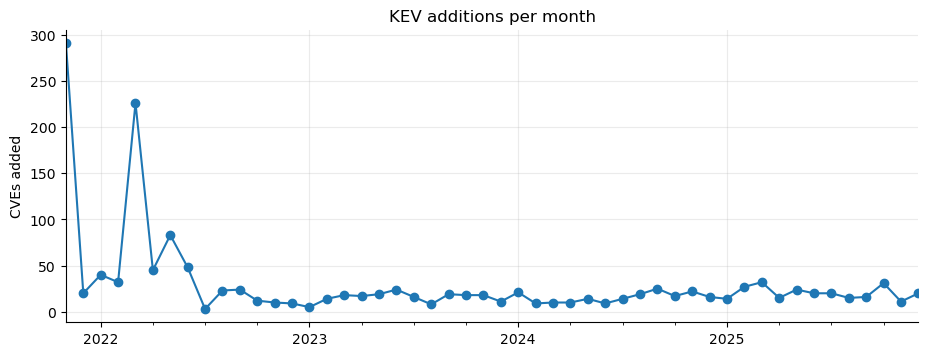

KEV rows with a published date: 1484 | added BEFORE published: 62


,count,pct
lag_days,,
before/at publish,179,12.1
<=30d,233,15.7
31-90d,105,7.1
91-180d,99,6.7
181-365d,130,8.8
1-2y,151,10.2
2-10y,522,35.2
>10y,65,4.4


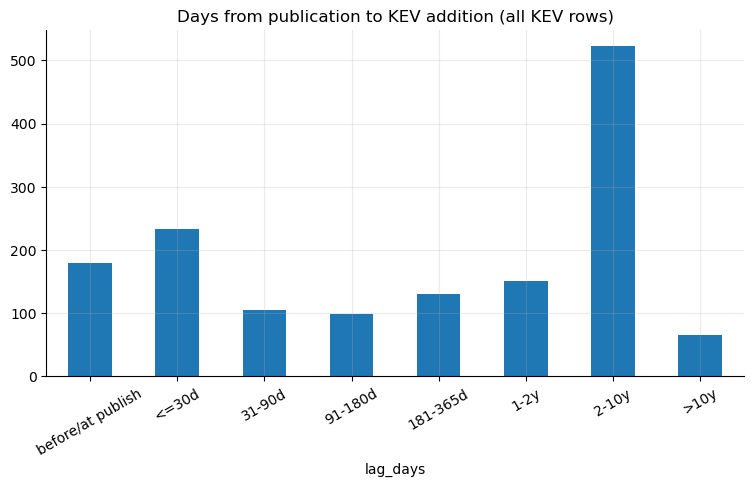

In [4]:
adds = kev.groupby(kev.date_added.dt.to_period("M")).size()
ax = adds.plot(kind="line", marker="o", figsize=(11, 3.8), title="KEV additions per month")
ax.set_xlabel(""); ax.set_ylabel("CVEs added")
plt.show()

kp = kev.merge(vuln[["cve_id", "published"]], on="cve_id", how="left")
kp["lag_days"] = (kp.date_added - kp.published).dt.days
print("KEV rows with a published date:", kp.published.notna().sum(), "| added BEFORE published:", int((kp.lag_days < 0).sum()))

bins = [-np.inf, 0, 30, 90, 180, 365, 730, 3650, np.inf]
labels = ["before/at publish", "<=30d", "31-90d", "91-180d", "181-365d", "1-2y", "2-10y", ">10y"]
lag_tbl = pd.cut(kp.lag_days, bins=bins, labels=labels).value_counts().reindex(labels)
lag_tbl = pd.DataFrame({"count": lag_tbl, "pct": (100 * lag_tbl / lag_tbl.sum()).round(1)})
display(lag_tbl)
lag_tbl["count"].plot(kind="bar", title="Days from publication to KEV addition (all KEV rows)", rot=30)
plt.show()

### 1b. How many exploited vulnerabilities were *visible* at snapshot time?
This is your **honest-limits** chart. If most later-exploited vulnerabilities had no EPSS and no exploit code at the end of their publish month, any snapshot model has a ceiling.

In [5]:
pos = snap[snap.label == 1]
neg = snap[snap.label == 0]

def visibility(df):
    return pd.Series({
        "n": len(df),
        "no signal row": 100 * (~df.has_signal_row).mean(),
        "epss >= 0.01": 100 * (df.epss >= 0.01).mean(),
        "epss >= 0.10": 100 * (df.epss >= 0.10).mean(),
        "epss >= 0.50": 100 * (df.epss >= 0.50).mean(),
        "any exploit code": 100 * df.any_exploit_code.mean(),
        "metasploit": 100 * df.metasploit.mean(),
        "nuclei": 100 * df.nuclei.mean(),
        "exploitdb": 100 * df.exploitdb.mean(),
        "poc_github": 100 * df.poc_github.mean(),
        "epss>=0.1 OR exploit code": 100 * ((df.epss >= 0.1) | (df.any_exploit_code == 1)).mean(),
    })

vis = pd.DataFrame({"later exploited": visibility(pos), "never added": visibility(neg)}).round(2)
display(vis)
print("Share of later-exploited vulnerabilities with NO warning (epss<0.1 and no exploit code):",
      round(100 * (1 - ((pos.epss >= 0.1) | (pos.any_exploit_code == 1)).mean()), 1), "%")

,later exploited,never added
n,122.00,87786.00
no signal row,7.38,6.60
epss >= 0.01,14.75,0.71
epss >= 0.10,6.56,0.13
epss >= 0.50,3.28,0.03
any exploit code,36.89,2.17
metasploit,2.46,0.05
nuclei,18.03,0.28
exploitdb,2.46,0.10
poc_github,31.15,1.94


Share of later-exploited vulnerabilities with NO warning (epss<0.1 and no exploit code): 63.1 %


**Finding 1:** _(write it here, e.g. "X% of later-exploited CVEs had no EPSS/exploit-code warning at snapshot")_

## 2. Reproduce the baselines

IBM's baselines: CVSS first, EPSS first, exploit code then EPSS. We recreate them on the 2024-2025 backtest.

Two honest touches: random tie-breaking (CVSS has many ties), and a **bootstrap over months** so you can see whether differences are bigger than noise. The cohort defaults to vulnerabilities published through **June 2025** so every row had at least 6 months to be exploited.

Cohort: 63,447 rows, 106 later exploited (0.167%)
Total exploited in cohort: 106


,CVSS3 first,EPSS first,"Exploit code, then EPSS",Random
top k,,,,
50,0,7,7,0
100,2,9,15,0
250,4,16,22,0
500,6,18,29,0
1000,9,21,35,3
2500,18,26,39,11
5000,34,36,46,12


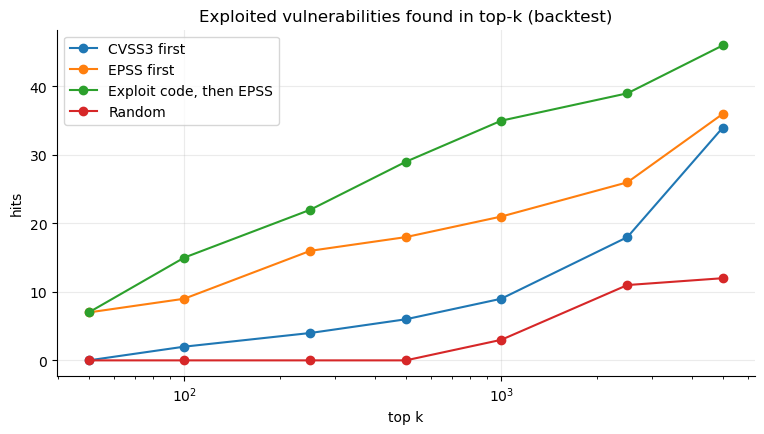

In [6]:
COHORT_END = "2025-06-30"
cohort = snap[snap.published <= COHORT_END].copy()
print(f"Cohort: {len(cohort):,} rows, {cohort.label.sum()} later exploited ({100*cohort.label.mean():.3f}%)")

cohort["s_cvss"] = cohort.cvss3_score.fillna(0)      # NOTE: blank CVSS is itself a leak signal, see section 5
cohort["s_epss"] = cohort.epss.fillna(0)
cohort["s_exploit_epss"] = cohort.any_exploit_code * 10 + cohort.s_epss
cohort["s_random"] = RNG.random(len(cohort))
SCORES = {"CVSS3 first": "s_cvss", "EPSS first": "s_epss", "Exploit code, then EPSS": "s_exploit_epss", "Random": "s_random"}

def topk(df, score, k):
    d = df.assign(_j=RNG.random(len(df))).sort_values([score, "_j"], ascending=False)
    return d.head(k)

ks = [50, 100, 250, 500, 1000, 2500, 5000]
tbl = pd.DataFrame({name: [int(topk(cohort, col, k).label.sum()) for k in ks] for name, col in SCORES.items()}, index=ks)
tbl.index.name = "top k"
print(f"Total exploited in cohort: {cohort.label.sum()}")
display(tbl)
ax = tbl.plot(marker="o", logx=True, title="Exploited vulnerabilities found in top-k (backtest)")
ax.set_ylabel("hits"); plt.show()

In [7]:
# Per-month top-k (rank within each month), then bootstrap over months for a CI on total hits
K_MONTH = 50
months = sorted(cohort.snapshot_month.unique())
per_month = {name: [int(topk(cohort[cohort.snapshot_month == m], col, K_MONTH).label.sum()) for m in months]
             for name, col in SCORES.items()}
pm = pd.DataFrame(per_month, index=months)
display(pm)

def boot_ci(arr, n=5000):
    arr = np.asarray(arr)
    draws = RNG.choice(arr, size=(n, len(arr)), replace=True).sum(axis=1)
    return arr.sum(), np.percentile(draws, 2.5), np.percentile(draws, 97.5)

summary = pd.DataFrame({n: boot_ci(pm[n]) for n in pm.columns}, index=["total hits", "ci_low", "ci_high"]).T
print(f"Top {K_MONTH} per month across {len(months)} months, 95% bootstrap CI over months")
display(summary)

,CVSS3 first,EPSS first,"Exploit code, then EPSS",Random
2024-01,0,1,2,1
2024-02,0,1,1,0
2024-03,0,1,2,0
2024-04,0,0,0,0
2024-05,0,1,1,0
2024-06,0,2,3,0
2024-07,0,0,0,0
2024-08,1,0,2,1
2024-09,1,2,2,0
2024-10,0,2,3,0


Top 50 per month across 18 months, 95% bootstrap CI over months


,total hits,ci_low,ci_high
CVSS3 first,6.0,2.0,11.0
EPSS first,19.0,12.0,27.0
"Exploit code, then EPSS",32.0,22.0,43.0
Random,3.0,0.0,6.0


**What to look for:** do the baselines overlap once you add CIs? If the intervals overlap, that supports your "top-500 counts are noisy" point. Any model you build later should be compared in this exact table.

**Finding 2:** _(write it here)_

## 3. Does severity separate exploited from not exploited?
KEV rate (%) by CVSS severity, EPSS bucket and exploit-code flags. Base rate is shown so lift is easy to read.

Base rate across all snapshot rows: 0.139%


,n,kev,rate_pct,lift
cvss3_severity,,,,
NONE,2,0,0.000,0.00
LOW,1930,1,0.052,0.37
MEDIUM,41397,12,0.029,0.21
HIGH,30537,50,0.164,1.18
CRITICAL,10953,59,0.539,3.88
MISSING,3089,0,0.000,0.00


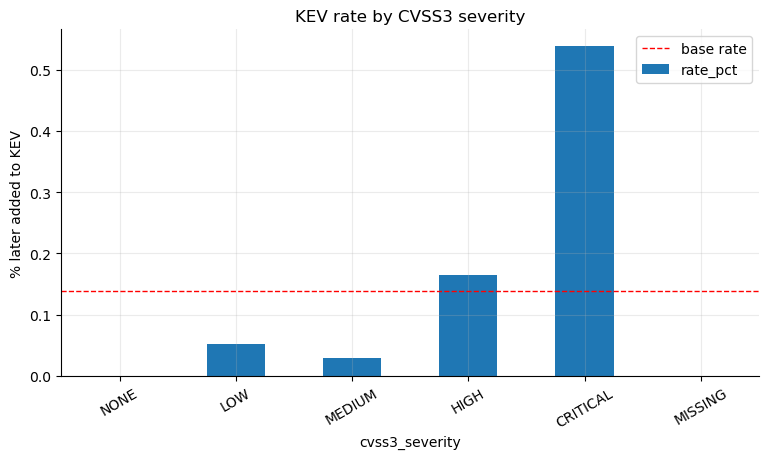

,n,kev,rate_pct,lift
epss_bucket,,,,
"(-0.001, 0.0005]",63260,59,0.093,0.67
"(0.0005, 0.001]",12619,15,0.119,0.86
"(0.001, 0.005]",5110,18,0.352,2.54
"(0.005, 0.01]",438,3,0.685,4.94
"(0.01, 0.05]",455,7,1.538,11.08
"(0.05, 0.1]",63,3,4.762,34.31
"(0.1, 0.5]",99,4,4.040,29.11
"(0.5, 1.0]",26,4,15.385,110.86
no score,5838,9,0.154,1.11


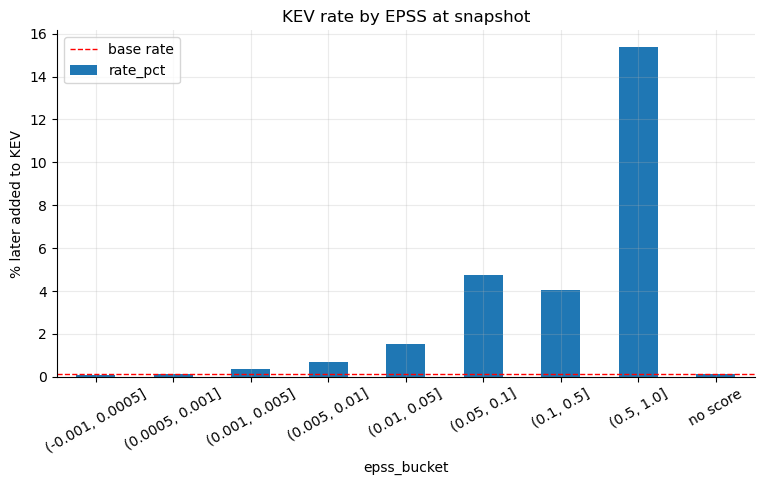

,n,kev,rate_pct,lift
n_flags,,,,
0,85956,77,0.090,0.65
1,1775,28,1.577,11.36
2,157,14,8.917,64.25
3,17,2,11.765,84.77
4,3,1,33.333,240.18


exploitdb


,n,kev,rate_pct,lift
exploitdb,,,,
0,87817,119,0.136,0.98
1,91,3,3.297,23.76


metasploit


,n,kev,rate_pct,lift
metasploit,,,,
0,87858,119,0.135,0.97
1,50,3,6.000,43.23


nuclei


,n,kev,rate_pct,lift
nuclei,,,,
0,87637,100,0.114,0.82
1,271,22,8.118,58.49


poc_github


,n,kev,rate_pct,lift
poc_github,,,,
0,86168,84,0.097,0.70
1,1740,38,2.184,15.74


In [8]:
base = 100 * snap.label.mean()
print(f"Base rate across all snapshot rows: {base:.3f}%")

def rate_by(df, col, min_n=1):
    g = df.groupby(col, dropna=False, observed=True).label.agg(n="size", kev="sum")
    g["rate_pct"] = (100 * g.kev / g.n).round(3)
    g["lift"] = (g.rate_pct / base).round(2)
    return g[g.n >= min_n]

def bar_rate(g, title):
    ax = g.rate_pct.plot(kind="bar", rot=30, title=title)
    ax.axhline(base, color="red", ls="--", lw=1, label="base rate")
    ax.set_ylabel("% later added to KEV"); ax.legend(); plt.show()

sev = snap.assign(cvss3_severity=snap.cvss3_severity.fillna("MISSING"))
g = rate_by(sev, "cvss3_severity").reindex(["NONE", "LOW", "MEDIUM", "HIGH", "CRITICAL", "MISSING"]).dropna(how="all")
display(g); bar_rate(g, "KEV rate by CVSS3 severity")

epss_bins = [-0.001, 0.0005, 0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1.0]
snap["epss_bucket"] = pd.cut(snap.epss, bins=epss_bins).astype(str).replace("nan", "no score")
g = rate_by(snap, "epss_bucket")
order = [str(x) for x in pd.cut(pd.Series([0.0002, 0.0007, 0.003, 0.008, 0.03, 0.07, 0.3, 0.8]), bins=epss_bins).cat.categories] + ["no score"]
g = g.reindex([o for o in order if o in g.index])
display(g); bar_rate(g, "KEV rate by EPSS at snapshot")

snap["n_flags"] = snap[["exploitdb", "metasploit", "nuclei", "poc_github"]].sum(axis=1)
g = rate_by(snap, "n_flags"); display(g)
for c in ["exploitdb", "metasploit", "nuclei", "poc_github"]:
    print(c); display(rate_by(snap, c))

**What to look for:** is the CVSS curve flat? Does CRITICAL beat HIGH by much? Is `MISSING` severity unusually high (a leak, see section 5)? Which single flag has the best lift?

**Finding 3:** _(write it here)_

## 4. Concentration: where do exploited vulnerabilities come from?
First from the KEV list itself (CISA's vendor names), then against the full snapshot using NIST's product list (`affected_products.csv`, `vulnerable == Y`).

KEV vendors: 243
Share of KEV from top 5 / 10 / 20 vendors: 44.5 55.4 66.6 %


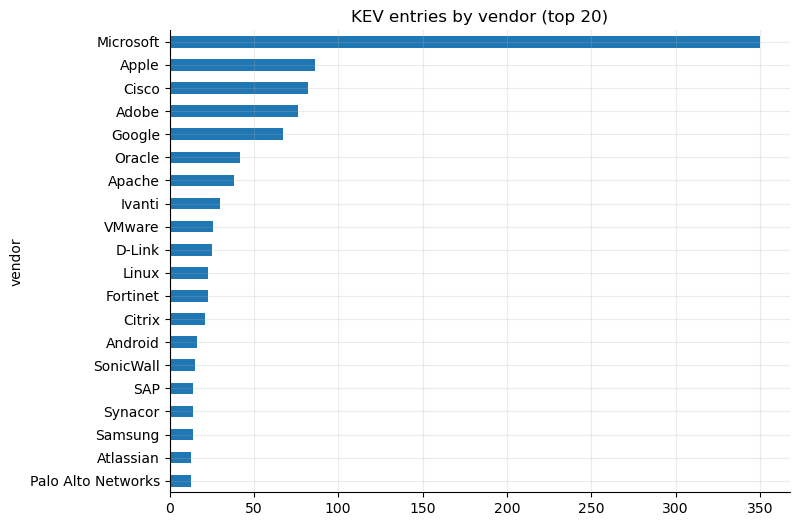

known_ransomware_use
Known       334
Unknown    1150
dtype: int64

known_ransomware_use,Known,Unknown
year,,
2021,84,227
2022,132,423
2023,43,144
2024,44,142
2025,31,214


In [9]:
top_v = kev.vendor.value_counts()
cum = (100 * top_v.cumsum() / top_v.sum()).round(1)
print("KEV vendors:", top_v.size)
print("Share of KEV from top 5 / 10 / 20 vendors:", *[cum.iloc[min(i, len(cum) - 1)] for i in (4, 9, 19)], "%")
top_v.head(20)[::-1].plot(kind="barh", title="KEV entries by vendor (top 20)", figsize=(8, 6))
plt.show()
display(kev.groupby("known_ransomware_use").size())
display(kev.assign(year=kev.date_added.dt.year).pivot_table(index="year", columns="known_ransomware_use", values="cve_id", aggfunc="count"))

In [10]:
# Load product table, keep only vulnerable products for the CVEs we care about
keep_ids = set(snap.cve_id) | set(kev.cve_id)
ap = pd.read_csv(DATA_DIR / "affected_products.csv", usecols=["cve_id", "vendor", "product", "vulnerable"], dtype=str)
ap = ap[(ap.vulnerable == "Y") & ap.cve_id.isin(keep_ids)]
ap_vendor = ap[["cve_id", "vendor"]].drop_duplicates()
ap_product = ap[["cve_id", "vendor", "product"]].drop_duplicates()
del ap
print("CVEs with at least one product:", ap_vendor.cve_id.nunique(), "of", len(keep_ids))
print("Share of snapshot CVEs with a product list:", round(snap.cve_id.isin(ap_vendor.cve_id).mean(), 3))

CVEs with at least one product: 63541 of 89270
Share of snapshot CVEs with a product list: 0.707


In [11]:
vp = ap_vendor.merge(snap[["cve_id", "label"]], on="cve_id")
vg = vp.groupby("vendor").label.agg(n="size", kev="sum")
vg["rate_pct"] = (100 * vg.kev / vg.n).round(2)
vg["lift"] = (vg.rate_pct / base).round(1)

print("Vendors with most later-exploited CVEs (2024-2025 snapshot):")
display(vg.sort_values("kev", ascending=False).head(15))
print("Highest KEV rate among vendors with >= 30 CVEs:")
display(vg[vg.n >= 30].sort_values("rate_pct", ascending=False).head(15))

# how concentrated are the positives in the vendor list?
pos_v = vg[vg.kev > 0].sort_values("kev", ascending=False)
print("Distinct vendors with >=1 later-exploited CVE:", len(pos_v),
      "| top 10 hold", round(100 * pos_v.kev.head(10).sum() / pos_v.kev.sum(), 1), "% of vendor-CVE positives")

Vendors with most later-exploited CVEs (2024-2025 snapshot):


,n,kev,rate_pct,lift
vendor,,,,
debian,1185,14,1.18,8.5
microsoft,2316,11,0.47,3.4
linux,8693,8,0.09,0.6
netapp,202,5,2.48,17.9
ivanti,268,5,1.87,13.5
apache,485,5,1.03,7.4
adobe,1589,4,0.25,1.8
vmware,57,4,7.02,50.6
cisco,495,3,0.61,4.4


Highest KEV rate among vendors with >= 30 CVEs:


,n,kev,rate_pct,lift
vendor,,,,
mitel,30,3,10.00,72.1
sonicwall,30,3,10.00,72.1
citrix,31,3,9.68,69.7
3ds,36,3,8.33,60.0
vmware,57,4,7.02,50.6
kentico,33,2,6.06,43.7
paloaltonetworks,65,3,4.62,33.3
solarwinds,61,2,3.28,23.6
canonical,67,2,2.99,21.5


Distinct vendors with >=1 later-exploited CVE: 74 | top 10 hold 40.0 % of vendor-CVE positives


In [12]:
# Weakness types (CWE)
cw = snap[["cve_id", "label", "cwe_ids"]].dropna(subset=["cwe_ids"]).copy()
cw["cwe"] = cw.cwe_ids.str.split(";")
cw = cw.explode("cwe")
cg = cw.groupby("cwe").label.agg(n="size", kev="sum")
cg["rate_pct"] = (100 * cg.kev / cg.n).round(2)
cg["lift"] = (cg.rate_pct / base).round(1)
cg = cg.join(cwe_names.set_index("cwe_id"), how="left")
print("CWE with highest KEV rate (n >= 100):")
display(cg[cg.n >= 100].sort_values("rate_pct", ascending=False).head(15))
print("CWE with most KEV positives:")
display(cg.sort_values("kev", ascending=False).head(10))

CWE with highest KEV rate (n >= 100):


,n,kev,rate_pct,lift,name
cwe,,,,,
CWE-822,109,2,1.83,13.2,Untrusted Pointer Dereference
CWE-611,233,4,1.72,12.4,Improper Restriction of XML External Entity Reference
CWE-552,155,2,1.29,9.3,Files or Directories Accessible to External Parties
CWE-290,242,3,1.24,8.9,Authentication Bypass by Spoofing
CWE-306,751,9,1.20,8.6,Missing Authentication for Critical Function
CWE-288,282,3,1.06,7.6,Authentication Bypass Using an Alternate Path or Channel
CWE-367,201,2,1.00,7.2,Time-of-check Time-of-use (TOCTOU) Race Condition
CWE-116,134,1,0.75,5.4,Improper Encoding or Escaping of Output
CWE-502,1087,8,0.74,5.3,Deserialization of Untrusted Data


CWE with most KEV positives:


,n,kev,rate_pct,lift,name
cwe,,,,,
CWE-22,2199,12,0.55,4.0,Improper Limitation of a Pathname to a Restricted Directory ('Path Traversal')
CWE-78,1690,10,0.59,4.3,Improper Neutralization of Special Elements used in an OS Command ('OS Command Injection')
CWE-306,751,9,1.20,8.6,Missing Authentication for Critical Function
CWE-502,1087,8,0.74,5.3,Deserialization of Untrusted Data
CWE-787,3174,7,0.22,1.6,Out-of-bounds Write
CWE-94,2180,6,0.28,2.0,Improper Control of Generation of Code ('Code Injection')
CWE-79,15664,5,0.03,0.2,Improper Neutralization of Input During Web Page Generation ('Cross-site Scripting')
CWE-284,2033,4,0.20,1.4,Improper Access Control
CWE-611,233,4,1.72,12.4,Improper Restriction of XML External Entity Reference


In [13]:
# Attack-detail columns (NOTE: blank when NIST has not scored the CVE yet, so treat as risky)
for c in ["attack_vector", "attack_complexity", "privileges_required", "user_interaction", "scope"]:
    display(rate_by(snap, c))
snap["rce_shape"] = ((snap.attack_vector == "NETWORK") & (snap.privileges_required == "NONE") & (snap.user_interaction == "NONE")).map({True: "network+noauth+noclick", False: "other"})
display(rate_by(snap, "rce_shape"))

,n,kev,rate_pct,lift
attack_vector,,,,
ADJACENT_NETWORK,2282,5,0.219,1.58
LOCAL,20935,18,0.086,0.62
NETWORK,60915,98,0.161,1.16
PHYSICAL,687,1,0.146,1.05
NaN,3089,0,0.000,0.00


,n,kev,rate_pct,lift
attack_complexity,,,,
HIGH,5520,10,0.181,1.30
LOW,79299,112,0.141,1.02
NaN,3089,0,0.000,0.00


,n,kev,rate_pct,lift
privileges_required,,,,
HIGH,7030,9,0.128,0.92
LOW,36529,24,0.066,0.48
NONE,41260,89,0.216,1.56
NaN,3089,0,0.000,0.00


,n,kev,rate_pct,lift
user_interaction,,,,
NONE,59241,111,0.187,1.35
REQUIRED,25578,11,0.043,0.31
NaN,3089,0,0.000,0.00


,n,kev,rate_pct,lift
scope,,,,
CHANGED,20103,14,0.070,0.5
UNCHANGED,64716,108,0.167,1.2
NaN,3089,0,0.000,0.0


,n,kev,rate_pct,lift
rce_shape,,,,
network+noauth+noclick,22895,75,0.328,2.36
other,65013,47,0.072,0.52


**What to look for:** how few vendors hold most positives; whether any CWE has large lift with a decent `n`; whether the "network, no privileges, no click" combo beats plain CVSS. These come from *NIST-analysed* rows only, so compare with section 5 before trusting them.

**Finding 4:** _(write it here)_

## 5. Leakage check: what does NIST's review process give away?
NIST analyses attacked vulnerabilities first and adds links to news and threat reports afterwards. Compare KEV vs non-KEV on the "risky" columns for 2024-2025. If they separate the groups strongly, they are leaking, not predicting. The 2026 data will be even more affected because many rows are not yet analysed.

In [14]:
snap["unreviewed"] = snap.nvd_status.isin(["Received", "Awaiting Analysis", "Undergoing Analysis"])
snap["cvss3_missing"] = snap.cvss3_score.isna()

leak = snap.groupby("label").agg(
    n=("cve_id", "size"),
    pct_unreviewed=("unreviewed", "mean"),
    pct_cvss3_missing=("cvss3_missing", "mean"),
    median_cpes=("n_affected_cpes", "median"),
    median_refs=("n_references", "median"),
    pct_zero_cpes=("n_affected_cpes", lambda s: (s == 0).mean()),
)
display(leak.round(3))
display(pd.crosstab(snap.nvd_status, snap.label, normalize="columns").round(3))
display(rate_by(snap, "nvd_status"))

,n,pct_unreviewed,pct_cvss3_missing,median_cpes,median_refs,pct_zero_cpes
label,,,,,,
0,87786,0.0,0.035,1.0,2.0,0.293
1,122,0.0,0.000,3.5,2.5,0.000


label,0,1
nvd_status,,
Analyzed,0.466,1.0
Awaiting Analysis,0.000,0.0
Deferred,0.293,0.0
Modified,0.241,0.0
Undergoing Analysis,0.000,0.0


,n,kev,rate_pct,lift
nvd_status,,,,
Analyzed,40988,122,0.298,2.15
Awaiting Analysis,1,0,0.000,0.00
Deferred,25728,0,0.000,0.00
Modified,21171,0,0.000,0.00
Undergoing Analysis,20,0,0.000,0.00


In [15]:
refs = pd.read_csv(DATA_DIR / "references.csv", usecols=["cve_id", "domain", "tags"])
refs = refs[refs.cve_id.isin(set(snap.cve_id))].copy()
refs["xforce"] = refs.domain.fillna("").str.contains("xforce", case=False)
refs["tag_exploit"] = refs.tags.fillna("").str.contains("Exploit")
refs["tag_thirdparty"] = refs.tags.fillna("").str.contains("Third Party Advisory")
rf = refs.groupby("cve_id")[["xforce", "tag_exploit", "tag_thirdparty"]].max()
snap = snap.drop(columns=[c for c in rf.columns if c in snap.columns]).join(rf, on="cve_id")
snap[rf.columns] = snap[rf.columns].fillna(False).astype(bool)
for c in rf.columns:
    print(c); display(rate_by(snap, c))

dom = refs[["cve_id", "domain"]].drop_duplicates().merge(snap[["cve_id", "label"]], on="cve_id")
dg = dom.groupby("domain").label.agg(n="size", kev="sum")
dg["rate_pct"] = (100 * dg.kev / dg.n).round(2)
dg["lift"] = (dg.rate_pct / base).round(1)
print("Reference domains with highest KEV lift (n >= 100). Likely post-attack links, so do NOT use them as features:")
display(dg[dg.n >= 100].sort_values("lift", ascending=False).head(20))

xforce


,n,kev,rate_pct,lift
xforce,,,,
False,87504,122,0.139,1.0
True,404,0,0.000,0.0


tag_exploit


,n,kev,rate_pct,lift
tag_exploit,,,,
False,70071,67,0.096,0.69
True,17837,55,0.308,2.22


tag_thirdparty


,n,kev,rate_pct,lift
tag_thirdparty,,,,
False,58649,57,0.097,0.7
True,29259,65,0.222,1.6


Reference domains with highest KEV lift (n >= 100). Likely post-attack links, so do NOT use them as features:


,n,kev,rate_pct,lift
domain,,,,
www.vicarius.io,126,12,9.52,68.6
vulncheck.com,115,4,3.48,25.1
support.broadcom.com,145,4,2.76,19.9
security.paloaltonetworks.com,111,3,2.70,19.5
nvd.nist.gov,137,3,2.19,15.8
forums.ivanti.com,268,5,1.87,13.5
www.openwall.com,1126,14,1.24,8.9
lists.apache.org,420,4,0.95,6.8
packetstorm.news,121,1,0.83,6.0


,single-feature AUC
"CVSS3 score (risky, blank=0)",0.753
n_affected_cpes (RISKY leak),0.742
any exploit code (clean),0.669
EPSS (clean),0.641
n_references (RISKY leak),0.629
has Exploit-tag link (RISKY leak),0.626
has xforce link (RISKY leak),0.497
cvss3 missing (RISKY leak),0.492


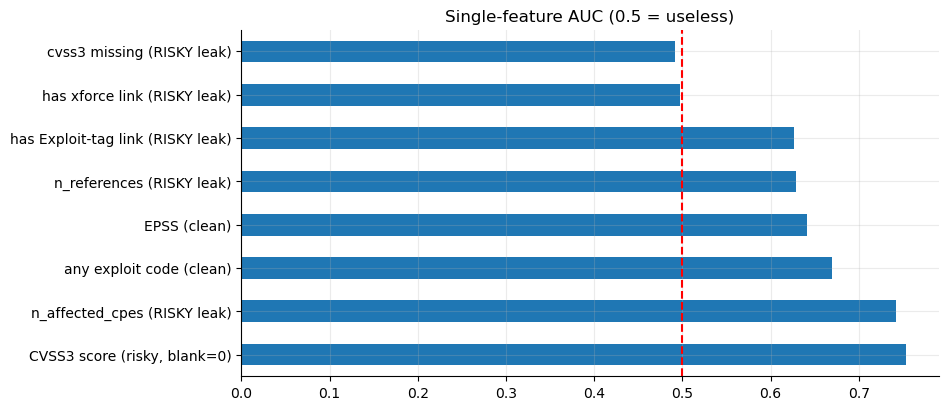

In [16]:
# Cheap leakage ablation: how well does each "risky" column alone rank the cohort vs a clean one?
from sklearn.metrics import roc_auc_score
c2 = snap[snap.published <= COHORT_END].copy()
feats = {
    "EPSS (clean)": c2.epss.fillna(0),
    "any exploit code (clean)": c2.any_exploit_code,
    "CVSS3 score (risky, blank=0)": c2.cvss3_score.fillna(0),
    "cvss3 missing (RISKY leak)": c2.cvss3_missing.astype(int),
    "n_affected_cpes (RISKY leak)": c2.n_affected_cpes,
    "n_references (RISKY leak)": c2.n_references,
    "has xforce link (RISKY leak)": c2.xforce.astype(int),
    "has Exploit-tag link (RISKY leak)": c2.tag_exploit.astype(int),
}
auc = pd.Series({k: roc_auc_score(c2.label, s) for k, s in feats.items()}).round(3).sort_values(ascending=False)
display(auc.to_frame("single-feature AUC"))
auc.plot(kind="barh", title="Single-feature AUC (0.5 = useless)").axvline(0.5, color="red", ls="--")
plt.show()

**What to look for:** a column whose AUC is far from 0.5 but that sits in the "risky" list is your "don't trust this" slide. Remember to say in the write-up which columns your final model used.

**Finding 5:** _(write it here)_

## 6. Momentum: does a vendor's recent KEV history predict the next exploited CVE?
For each snapshot CVE and each vendor in its product list, count KEV additions for that vendor in the 12 months **before the snapshot month** (strictly earlier, so no peeking). Take the max over the CVE's vendors.

Caveat: CVEs without a product list (unreviewed) get 0. Section 7 handles those via description text.

,n,kev,rate_pct,lift
mom_bucket,,,,
0,64954,50,0.077,0.55
1-2,5075,20,0.394,2.84
3-5,5460,10,0.183,1.32
6-10,6889,16,0.232,1.67
11-25,2980,15,0.503,3.62
26+,2550,11,0.431,3.11


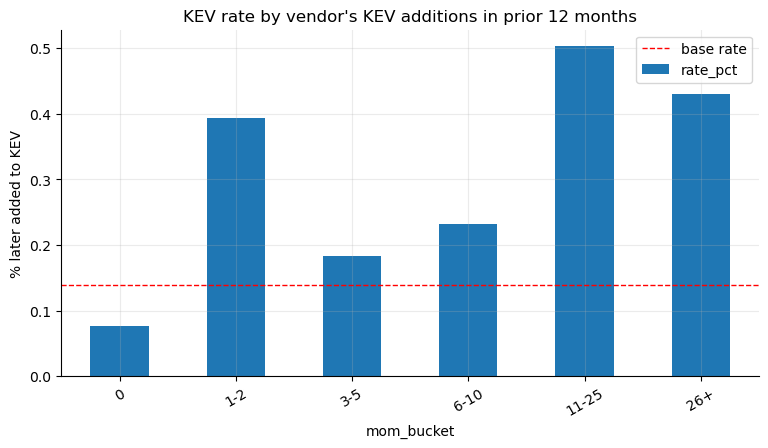

In [17]:
kv = ap_vendor.merge(kev[["cve_id", "date_added"]], on="cve_id")
kv["m"] = kv.date_added.dt.to_period("M")
counts = kv.groupby(["vendor", "m"]).size().unstack(fill_value=0)
months_idx = pd.period_range("2021-11", "2026-01", freq="M")
counts = counts.reindex(columns=months_idx, fill_value=0)
cumc = counts.cumsum(axis=1)

def colp(p):
    return cumc[p] if p in cumc.columns else pd.Series(0, index=cumc.index)

rows = []
for s in sorted(snap.snapshot_month.unique()):
    p = pd.Period(s, "M")
    rows.append(pd.DataFrame({
        "snapshot_month": s, "vendor": cumc.index,
        "kev_prior12": (colp(p - 1) - colp(p - 13)).values,
        "kev_prior_all": colp(p - 1).values,
    }))
vm = pd.concat(rows)

pairs = (snap[["cve_id", "snapshot_month"]].merge(ap_vendor, on="cve_id")
         .merge(vm, on=["snapshot_month", "vendor"], how="left").fillna({"kev_prior12": 0, "kev_prior_all": 0}))
mom = pairs.groupby("cve_id")[["kev_prior12", "kev_prior_all"]].max()
snap = snap.drop(columns=[c for c in mom.columns if c in snap.columns]).join(mom, on="cve_id")
snap[mom.columns] = snap[mom.columns].fillna(0)

snap["mom_bucket"] = pd.cut(snap.kev_prior12, [-1, 0, 2, 5, 10, 25, 1e9], labels=["0", "1-2", "3-5", "6-10", "11-25", "26+"])
g = rate_by(snap, "mom_bucket")
display(g); bar_rate(g, "KEV rate by vendor's KEV additions in prior 12 months")

In [18]:
c3 = snap[snap.published <= COHORT_END]
print("AUC, vendor prior-12m KEV count:", round(roc_auc_score(c3.label, c3.kev_prior12), 3))
print("AUC, EPSS:", round(roc_auc_score(c3.label, c3.epss.fillna(0)), 3))
print("AUC, CVSS3:", round(roc_auc_score(c3.label, c3.cvss3_score.fillna(0)), 3))
for name, col in {"vendor momentum": "kev_prior12", "EPSS": "epss", "CVSS3": "cvss3_score"}.items():
    print(f"top-500 hits | {name}:", int(topk(c3.assign(**{col: c3[col].fillna(0)}), col, 500).label.sum()))

AUC, vendor prior-12m KEV count: 0.661
AUC, EPSS: 0.641
AUC, CVSS3: 0.753
top-500 hits | vendor momentum: 3
top-500 hits | EPSS: 18
top-500 hits | CVSS3: 6


**What to look for:** a rising rate across buckets, and how momentum compares with EPSS and CVSS on both AUC and top-500 hits. Momentum should be strongest on CVEs EPSS has not noticed yet, so try slicing `c3` by `epss < 0.01` and re-checking.

**Finding 6:** _(write it here)_

## 7. Description text: do phrases carry signal?
Every CVE has a description, including the 51k unreviewed ones, so text is the only feature that works for all of them. Start with a hand-picked phrase list. Later, swap this for **IBM Granite embeddings** to see if they add lift beyond these keywords.

In [19]:
desc = snap.description.fillna("").str.lower()
phrases = [
    "remote code execution", "execute arbitrary code", "execute arbitrary commands", "command injection", "os command",
    "authentication bypass", "bypass authentication", "unauthenticated", "without authentication", "deserialization",
    "sql injection", "path traversal", "directory traversal", "use after free", "buffer overflow", "out-of-bounds",
    "cross-site scripting", "xss", "privilege escalation", "arbitrary file upload", "arbitrary file", "ssrf", "default credentials",
    "hard-coded", "firewall", "vpn", "gateway", "router", "wordpress plugin", "admin panel",
]
out = []
for p in phrases:
    m = desc.str.contains(p, regex=False)
    n = int(m.sum()); k = int(snap.label[m].sum())
    out.append((p, n, k, round(100 * k / n, 3) if n else np.nan, round((100 * k / n) / base, 2) if n else np.nan))
ph = pd.DataFrame(out, columns=["phrase", "n", "kev", "rate_pct", "lift"]).sort_values("lift", ascending=False)
display(ph)

,phrase,n,kev,rate_pct,lift
29,admin panel,92,2,2.174,15.66
6,bypass authentication,258,5,1.938,13.96
25,vpn,296,4,1.351,9.74
24,firewall,307,3,0.977,7.04
2,execute arbitrary commands,590,5,0.847,6.11
5,authentication bypass,623,5,0.803,5.78
7,unauthenticated,6335,37,0.584,4.21
11,path traversal,1439,8,0.556,4.01
0,remote code execution,3618,18,0.498,3.58
9,deserialization,961,4,0.416,3.00


In [20]:
# Data-driven version: which words are most over-represented in later-exploited descriptions?
from sklearn.feature_extraction.text import CountVectorizer
tr = snap[snap.published <= COHORT_END]
cv = CountVectorizer(ngram_range=(1, 2), min_df=20, binary=True, stop_words="english", max_features=50000)
X = cv.fit_transform(tr.description.fillna(""))
y = tr.label.values
n_pos = y.sum(); n_all = len(y)
pos_df = np.asarray(X[y == 1].sum(axis=0)).ravel()
all_df = np.asarray(X.sum(axis=0)).ravel()
terms = np.array(cv.get_feature_names_out())
tab = pd.DataFrame({"term": terms, "docs": all_df, "kev_docs": pos_df})
tab["rate_pct"] = 100 * tab.kev_docs / tab.docs
tab["lift"] = tab.rate_pct / (100 * n_pos / n_all)
display(tab[(tab.kev_docs >= 5)].sort_values("lift", ascending=False).head(25))

,term,docs,kev_docs,rate_pct,lift
6120,exploited wild,20,6,30.000000,179.566981
14580,wild,43,6,13.953488,83.519526
11250,remote unauthenticated,303,12,3.960396,23.705212
3578,bypass authentication,204,5,2.450980,14.670505
8017,ivanti,207,5,2.415459,14.457889
4264,configurations,216,5,2.314815,13.855477
1308,2025,428,9,2.102804,12.586471
3591,bypass vulnerability,256,5,1.953125,11.690559
13328,unauthenticated attacker,923,16,1.733478,10.375846
13333,unauthenticated remote,622,9,1.446945,8.660787


**What to look for:** product/vendor names and attack-type words that carry lift. If the top terms are mostly vendor names, that backs the vendor-prior idea. This is also where Granite embeddings plug in. Do they beat this baseline, or only match it?

**Finding 7:** _(write it here)_

## 8. Look at the 2026 scoreboard
Check what you will actually be ranking. Remember this table only has `epss` and the four exploit flags. Everything else comes from `vulnerabilities.csv` and must be used carefully.

In [21]:
print(board.shape, "| snapshot months:", sorted(board.snapshot_month.unique()))
display(board.groupby("snapshot_month").agg(n=("cve_id", "size"), epss_missing=("epss", lambda s: s.isna().mean()),
                                            exploit_any=("exploitdb", lambda s: np.nan)).drop(columns="exploit_any").round(3))
board["any_exploit_code"] = (board[["exploitdb", "metasploit", "nuclei", "poc_github"]].sum(axis=1) > 0).astype(int)
print("Share with any exploit code:", round(board.any_exploit_code.mean(), 4), "| EPSS >= 0.1:", round((board.epss >= 0.1).mean(), 4))
print("June published rows are scored from July signals:", int(((board.published.dt.month == 6) & (board.snapshot_month == "2026-07")).sum()))

b = board.merge(vuln[["cve_id", "nvd_status", "cvss3_score", "n_affected_cpes", "n_references"]], on="cve_id", how="left")
display(pd.crosstab(b.snapshot_month, b.nvd_status, normalize="index").round(3))
print("Unreviewed overall:", round(b.nvd_status.isin(["Received", "Awaiting Analysis", "Undergoing Analysis"]).mean(), 3),
      "| no CVSS3:", round(b.cvss3_score.isna().mean(), 3), "| zero products:", round((b.n_affected_cpes == 0).mean(), 3))

(72670, 8) | snapshot months: ['2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-07', '2026-08', '2026-09']


,n,epss_missing
snapshot_month,,
2026-01,4295,0.010
2026-02,4603,0.003
2026-03,6227,0.036
2026-04,5801,0.026
2026-05,6922,0.005
2026-07,17678,0.006
2026-08,12242,0.025
2026-09,14902,0.037


Share with any exploit code: 0.0226 | EPSS >= 0.1: 0.0009
June published rows are scored from July signals: 7921


nvd_status,Analyzed,Awaiting Analysis,Deferred,Modified,Received,Undergoing Analysis
snapshot_month,,,,,,
2026-01,0.490,0.000,0.403,0.106,0.000,0.000
2026-02,0.547,0.000,0.341,0.112,0.000,0.000
2026-03,0.605,0.031,0.255,0.108,0.000,0.001
2026-04,0.562,0.042,0.278,0.118,0.000,0.001
2026-05,0.430,0.047,0.381,0.126,0.000,0.016
2026-07,0.473,0.049,0.395,0.079,0.000,0.005
2026-08,0.303,0.096,0.434,0.030,0.133,0.003
2026-09,0.307,0.155,0.387,0.011,0.133,0.007


Unreviewed overall: 0.125 | no CVSS3: 0.087 | zero products: 0.496


In [22]:
# Baseline top-500 files for the scoreboard (use these to sanity-check your own output format)
board["s_exploit_epss"] = board.any_exploit_code * 10 + board.epss.fillna(0)
base500 = board.sort_values("s_exploit_epss", ascending=False).head(500)[["cve_id"]]
print(base500.shape, base500.cve_id.is_unique)
# base500.to_csv("top500_baseline.csv", index=False)   # uncomment to save

(500, 1) True


## Findings log
Copy your best findings here. They become the demo.

1. **Visibility ceiling:** 
2. **Baselines are noisy:** 
3. **Severity vs exploitation:** 
4. **Concentration:** 
5. **Leakage:** 
6. **Momentum:** 
7. **Text signal:** 

### Next step after exploration
Pick the 3-4 strongest, build a gradient-boosted model on **clean features only** (EPSS, exploit flags, vendor momentum, text features), train on 2024 and test on 2025, then generate `top500.csv` for the scoreboard. Add Granite embeddings and one-line explanations on top.